# SGD Perceptron: UFC fight outcomes

## Question

Can pre-fight fighter records predict whether the Red or Blue corner wins? The reference study is McQuaide (2019), *Applying Machine Learning Algorithms to Predict UFC Fight Outcomes*. Its original dataset link is unavailable, so this project uses the public TidyTuesday UFC dataset and restricts it to 2010–2019.

## How this model works

A linear classifier learns one weighted score from the fighter statistics. Stochastic Gradient Descent updates those weights after examples, while perceptron loss focuses on correcting mistakes. The predicted corner is the side with the larger score.

### Why include it

This is the paper's linear baseline. It trains quickly and is easy to interpret at a high level, but a single linear boundary cannot capture complex interactions between fighter attributes.

### Settings used

Perceptron loss; random seed 42; default regularization and learning-rate settings from scikit-learn.

## Shared evaluation design

Each notebook uses the same 48 pre-fight fighter fields, date ordering, 20 expanding-window time-series folds, and preprocessing as the main project. Each test fold occurs after its training data. Numeric gaps are filled with the training-fold median, stances are one-hot encoded, and features are scaled inside the fold. No-contests are excluded. The selected years have no draws.

The saved tables below let you inspect the completed run immediately. Run the code cells to reproduce the results on your machine.


## Saved run results

These are the results from the completed 20-fold chronological run. The next cells rerun this model from the bundled dataset. Accuracy is the share of bouts assigned to the correct corner. Macro-F1 computes F1 separately for Red and Blue, then averages the two scores equally.

| Measure | Result |
|---|---:|
| Mean training accuracy | 56.4% |
| Mean test accuracy | 54.1% |
| Test accuracy standard deviation across folds | 4.7% |
| Mean test macro-F1 | 0.523 |
| Paper test accuracy | 58.0% |
| Difference from paper | -4.0% |

The always-Red baseline is 58.2% accuracy on this slice. This period contains 4,073 bouts: 2,372 Red wins and 1,701 Blue wins. It contains no draws, so results here are binary despite the reference paper's three-outcome task.

![Twenty chronological test-fold accuracies](../results/plots/01_sgd_perceptron_accuracy.png)

### Fold-by-fold results

| Fold | Train accuracy | Test accuracy | Test macro-F1 |
|---:|---:|---:|---:|
| 1 | 65.7% | 52.8% | 0.521 |
| 2 | 59.9% | 45.6% | 0.436 |
| 3 | 53.1% | 50.8% | 0.483 |
| 4 | 58.5% | 52.3% | 0.507 |
| 5 | 56.0% | 52.8% | 0.520 |
| 6 | 58.1% | 57.0% | 0.530 |
| 7 | 54.0% | 59.6% | 0.551 |
| 8 | 57.2% | 57.0% | 0.556 |
| 9 | 56.5% | 47.7% | 0.462 |
| 10 | 56.8% | 62.7% | 0.586 |
| 11 | 56.3% | 55.4% | 0.531 |
| 12 | 57.7% | 61.1% | 0.570 |
| 13 | 54.0% | 47.7% | 0.475 |
| 14 | 56.0% | 57.5% | 0.559 |
| 15 | 56.9% | 57.5% | 0.562 |
| 16 | 53.9% | 52.3% | 0.522 |
| 17 | 56.6% | 50.3% | 0.499 |
| 18 | 55.4% | 58.5% | 0.585 |
| 19 | 52.6% | 50.8% | 0.481 |
| 20 | 53.3% | 51.8% | 0.518 |

**How to read this model's result:** A small train-test gap is consistent with a simple boundary. If results are near the always-Red baseline, the model may not be extracting much signal beyond the class imbalance.


In [1]:
from pathlib import Path
import sys
from IPython.display import display
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import TimeSeriesSplit

search_paths = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in search_paths if (path / "src" / "train.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Open the UFC project folder in VS Code so the notebook can locate src/train.py.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.train import N_SPLITS, load_data, make_models, make_pipeline

data, X, y = load_data()
model_name = 'SGD perceptron'
model = make_models()[model_name]
print(f"Loaded {len(data):,} bouts from {data['date'].min().date()} to {data['date'].max().date()}")
print("Outcome counts:")
display(y.value_counts().rename_axis("corner").to_frame("bouts"))

Loaded 4,073 bouts from 2010-03-21 to 2019-12-21
Outcome counts:


,bouts
corner,
Red,2372
Blue,1701


In [2]:
fold_rows = []
splitter = TimeSeriesSplit(n_splits=N_SPLITS)

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    pipeline = make_pipeline(model)
    pipeline.fit(X_train, y_train)
    train_prediction = pipeline.predict(X_train)
    test_prediction = pipeline.predict(X_test)
    fold_rows.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "train_accuracy": accuracy_score(y_train, train_prediction),
        "test_accuracy": accuracy_score(y_test, test_prediction),
        "test_macro_f1": f1_score(y_test, test_prediction, average="macro", zero_division=0),
    })

fold_results = pd.DataFrame(fold_rows)
summary = pd.DataFrame([{
    "model": model_name,
    "mean_train_accuracy": fold_results["train_accuracy"].mean(),
    "mean_test_accuracy": fold_results["test_accuracy"].mean(),
    "test_accuracy_sd": fold_results["test_accuracy"].std(),
    "mean_test_macro_f1": fold_results["test_macro_f1"].mean(),
}])
display(summary.style.format({
    "mean_train_accuracy": "{:.1%}",
    "mean_test_accuracy": "{:.1%}",
    "test_accuracy_sd": "{:.1%}",
    "mean_test_macro_f1": "{:.3f}",
}))
display(fold_results.style.format({
    "train_accuracy": "{:.1%}",
    "test_accuracy": "{:.1%}",
    "test_macro_f1": "{:.3f}",
}))

,model,mean_train_accuracy,mean_test_accuracy,test_accuracy_sd,mean_test_macro_f1
0,SGD perceptron,56.4%,54.1%,4.7%,0.523


,fold,train_rows,test_rows,train_accuracy,test_accuracy,test_macro_f1
0,1,213,193,65.7%,52.8%,0.521
1,2,406,193,59.9%,45.6%,0.436
2,3,599,193,53.1%,50.8%,0.483
3,4,792,193,58.5%,52.3%,0.507
4,5,985,193,56.0%,52.8%,0.520
5,6,1178,193,58.1%,57.0%,0.530
6,7,1371,193,54.0%,59.6%,0.551
7,8,1564,193,57.2%,57.0%,0.556
8,9,1757,193,56.5%,47.7%,0.462
9,10,1950,193,56.8%,62.7%,0.586


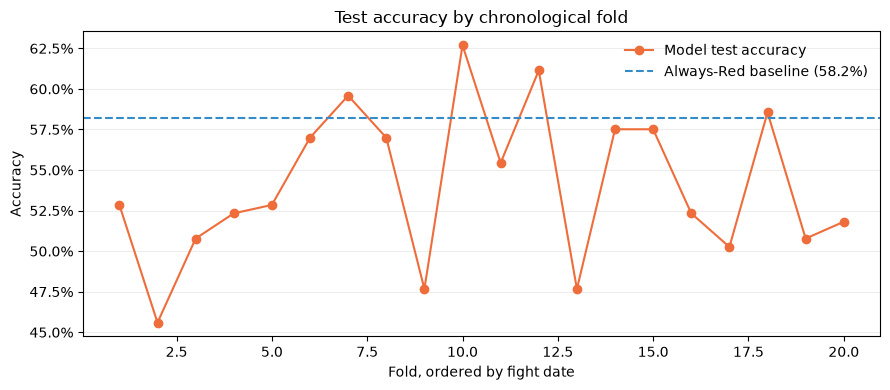

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fold_results["fold"], fold_results["test_accuracy"], marker="o", color="#ef6c3b", label="Model test accuracy")
ax.axhline(0.582, color="#338cc7", linestyle="--", label="Always-Red baseline (58.2%)")
ax.set(title="Test accuracy by chronological fold", xlabel="Fold, ordered by fight date", ylabel="Accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.22)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Interpretation

A small train-test gap is consistent with a simple boundary. If results are near the always-Red baseline, the model may not be extracting much signal beyond the class imbalance.

The reference scores are not a like-for-like benchmark because its original sample spans 1997–2019, has 134 features, and includes three outcomes. This dataset starts in 2010 and the selected slice has only Red and Blue outcomes. Treat the paper comparison as approximate.

**Sources:** [McQuaide (2019) report](https://cs229.stanford.edu/proj2019aut/data/assignment_308832_raw/26647731.pdf) · [TidyTuesday dataset documentation](https://github.com/rfordatascience/tidytuesday/tree/main/data/2026/2026-07-07)
